# 05 · Benchmark of SSS against AlphaMissense, ESM-1v and EVE

ClinVar GAA missense variants (the snapshot distributed with the EVE GAA model). P/LP = pathogenic or likely pathogenic, B/LB = benign or likely benign. The benchmark set contains the P/LP and B/LB variants scored by all four predictors.

In [1]:
%matplotlib inline
import sys, json, inspect, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from gaa_hotspot import data, network, stats, ml, figures as F
from gaa_hotspot import sss as sss_mod
from gaa_hotspot.common import AA, MODEL_ORDER, MODEL_NAMES, config, raw, read_processed, table, load_values
from gaa_hotspot.plotting import apply_style, MODEL_COLOURS, MODEL_LABELS, MODEL_SHORT, V7_MODEL_ORDER

apply_style()
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
cfg = config()
V = load_values()
print("project root:", ROOT)

project root: Pompe-GAA-Hotspots


## 1. ClinVar labels

In [2]:
eve = pd.read_csv(raw("predictors", "EVE_LYAG_HUMAN.csv"), usecols=["wt_aa", "position", "mt_aa", "ClinVar_ClinicalSignificance", "EVE_scores_ASM"])
print("EVE file:", eve.shape)
clin = eve.dropna(subset=["ClinVar_ClinicalSignificance"]).rename(columns={"wt_aa": "wt", "position": "residue", "mt_aa": "mt",
                                                                          "ClinVar_ClinicalSignificance": "clinvar", "EVE_scores_ASM": "EVE"})
clin.clinvar.value_counts().to_frame("variants")

EVE file: (19040, 5)


,variants
clinvar,
Uncertain significance,414
Pathogenic,41
Conflicting interpretations of pathogenicity,40
Likely pathogenic,31
Pathogenic/Likely pathogenic,25
Likely benign,9
Benign,6
Benign/Likely benign,5
"Benign, other",2


In [3]:
b = cfg["benchmark"]
def klass(s):
    if s in b["pathogenic"]: return "Pathogenic"
    if s in b["benign"]: return "Benign"
    if s.startswith("Uncertain"): return "VUS"
    if s.startswith("Conflicting"): return "Conflicting"
    return "Other"
clin["class"] = clin.clinvar.map(klass)
clin["class"].value_counts().to_frame("variants")

,variants
class,
VUS,414
Pathogenic,97
Conflicting,40
Benign,23


## 2. Predictor scores

ESM-1v reports a log-likelihood ratio (lower = more damaging), so it is negated; for every score, higher = more damaging.

In [4]:
am = pd.read_csv(raw("predictors", "AlphaMissense_P10253.tsv"), sep="\t").rename(columns={"position": "residue", "a.a.1": "wt", "a.a.2": "mt", "pathogenicity score": "AlphaMissense"})
esm = pd.read_csv(raw("predictors", "ESM1v_P10253.csv"))
esm["wt"], esm["mt"], esm["residue"], esm["ESM-1v"] = esm.variant.str[0], esm.variant.str[-1], esm.pos, -esm.score
sss = read_processed("sss_all_substitutions.csv").rename(columns={"sss": "SSS", "evoscore_scaled": "EVOscore", "di_scaled": "DI"})
v = (clin.merge(am[["residue", "wt", "mt", "AlphaMissense"]], on=["residue", "wt", "mt"], how="left")
         .merge(esm[["residue", "wt", "mt", "ESM-1v"]], on=["residue", "wt", "mt"], how="left")
         .merge(sss[["residue", "wt", "mt", "SSS", "EVOscore", "DI"]], on=["residue", "wt", "mt"], how="left"))
tools = ["SSS", "AlphaMissense", "ESM-1v", "EVE"]
v["all_four_scores"] = v[tools].notna().all(axis=1)
binary = v[v["class"].isin(["Pathogenic", "Benign"])]
print("P/LP + B/LB variants:", len(binary))
print("coverage:", {t: int(binary[t].notna().sum()) for t in tools}, "(SSS needs a residue in the structure, 81-952)")
bench = binary[binary.all_four_scores].copy()
bench["y"] = (bench["class"] == "Pathogenic").astype(int)
print(f"benchmark set: {len(bench)} variants = {bench.y.sum()} P/LP + {(1 - bench.y).sum()} B/LB")

P/LP + B/LB variants: 120
coverage: {'SSS': 111, 'AlphaMissense': 116, 'ESM-1v': 120, 'EVE': 104} (SSS needs a residue in the structure, 81-952)
benchmark set: 102 variants = 89 P/LP + 13 B/LB


## 3. Discrimination

ROC AUC with DeLong and stratified-bootstrap (2,000 resamples) 95% CIs, Spearman correlation with the class, Mann–Whitney U test. EVOscore and DI are the two SSS components.

In [5]:
from scipy import stats as ss
rng = np.random.default_rng(cfg["seed"])
yb = bench.y.values
rows = []
for t in tools + ["EVOscore", "DI"]:
    s = bench[t].values
    a, lo, hi = stats.delong_ci(yb, s)
    blo, bhi = stats.bootstrap_auc_ci(yb, s, b["bootstrap"], rng)
    rho, rp = ss.spearmanr(s, yb)
    rows.append({"predictor": t, "ROC AUC": a, "DeLong CI": f"{lo:.3f}-{hi:.3f}", "bootstrap CI": f"{blo:.3f}-{bhi:.3f}",
                 "Spearman r": rho, "Spearman P": rp, "Mann-Whitney P": ss.mannwhitneyu(s[yb == 1], s[yb == 0]).pvalue})
perf = pd.DataFrame(rows)
stored = pd.read_csv(table("benchmark_performance.csv"))
print("identical to results/tables/benchmark_performance.csv:", np.allclose(perf["ROC AUC"], stored.roc_auc))
perf

identical to results/tables/benchmark_performance.csv: True


,predictor,ROC AUC,DeLong CI,bootstrap CI,Spearman r,Spearman P,Mann-Whitney P
0,SSS,0.9533,0.912-0.995,0.906-0.988,0.5237,1.6198e-08,1.4538e-07
1,AlphaMissense,0.9689,0.937-1.000,0.933-0.996,0.5417,4.1250e-09,5.3630e-08
2,ESM-1v,0.9473,0.894-1.000,0.887-0.990,0.5167,2.7028e-08,2.1262e-07
3,EVE,0.9360,0.853-1.000,0.841-0.993,0.5037,6.7769e-08,4.2479e-07
4,EVOscore,0.9494,0.906-0.993,0.903-0.986,0.5199,2.1467e-08,1.7912e-07
5,DI,0.8518,0.753-0.951,0.742-0.937,0.4068,2.2079e-05,4.4421e-05


Paired DeLong tests of SSS against each predictor:

In [6]:
pd.DataFrame([{"comparison": f"SSS vs {t}", **stats.delong_test(yb, bench.SSS.values, bench[t].values)} for t in ["AlphaMissense", "ESM-1v", "EVE", "EVOscore", "DI"]]).round(4)

,comparison,auc_a,auc_b,difference,z,p
0,SSS vs AlphaMissense,0.9533,0.9689,-0.0156,-0.9330,0.3508
1,SSS vs ESM-1v,0.9533,0.9473,0.0061,0.3111,0.7557
2,SSS vs EVE,0.9533,0.9360,0.0173,0.4769,0.6335
3,SSS vs EVOscore,0.9533,0.9494,0.0039,0.3636,0.7162
4,SSS vs DI,0.9533,0.8518,0.1016,2.7240,0.0065


### Figure 6 — ROC curves and summary table

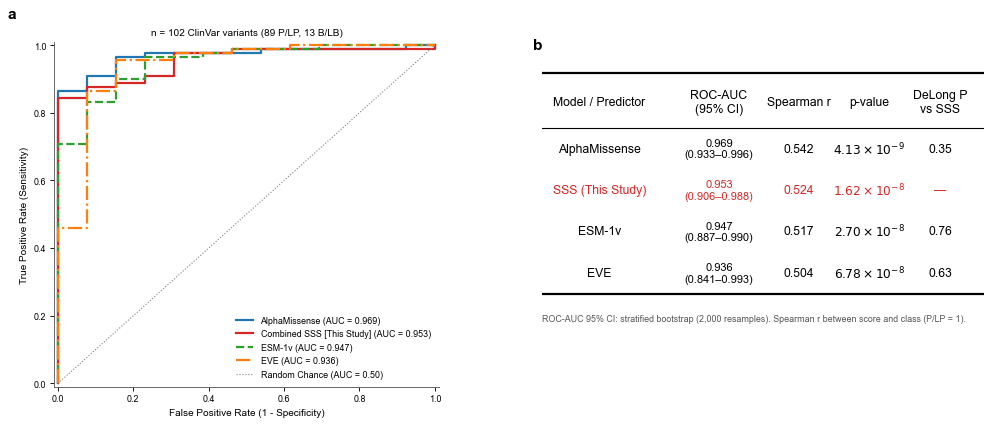

In [7]:
bperf = stored.set_index("predictor")
F.fig6_benchmark(bench, bperf, pd.read_csv(table("benchmark_delong_vs_sss.csv")))
plt.show()

### Supplementary Figure S11 — AUC ranking and score separation

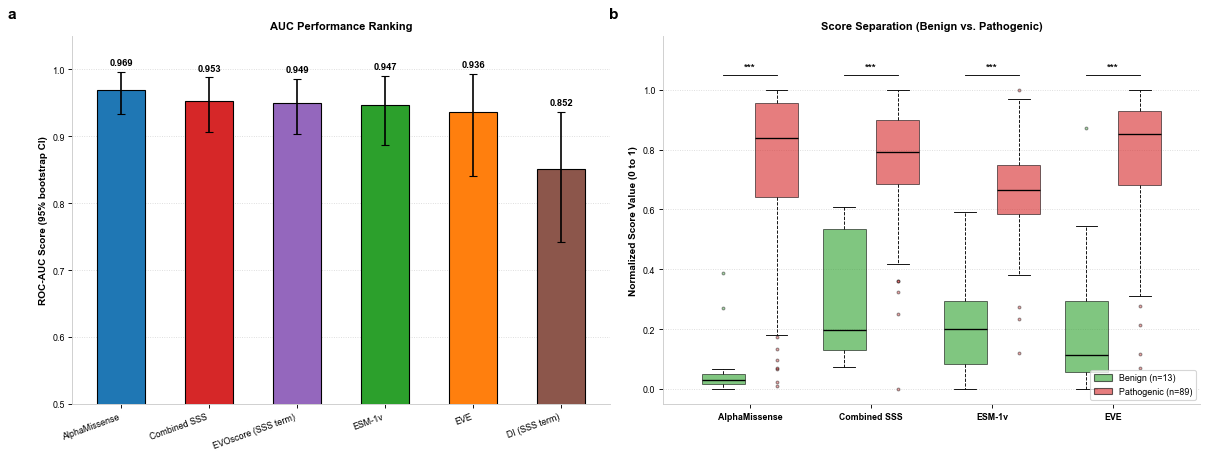

In [8]:
F.figS_benchmark_separation(bench, bperf)
plt.show()

## 4. SSS classification thresholds

The 0.5 and 0.6 cut-offs of the severity classes (Fig. 5a) and the Youden-optimal cut-off (derived from the same variants, so optimistic):

In [9]:
from sklearn.metrics import roc_curve
fpr, tpr, thr = roc_curve(yb, bench.SSS)
rows = []
for name, cut in [("0.5", 0.5), ("0.6", 0.6), ("Youden (in-sample)", float(thr[np.argmax(tpr - fpr)]))]:
    pred = (bench.SSS.values >= cut).astype(int)
    tp, fn = int(((pred == 1) & (yb == 1)).sum()), int(((pred == 0) & (yb == 1)).sum())
    tn, fp = int(((pred == 0) & (yb == 0)).sum()), int(((pred == 1) & (yb == 0)).sum())
    rows.append({"cut-off": name, "value": round(cut, 3), "TP": tp, "FN": fn, "TN": tn, "FP": fp,
                 "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp), "accuracy": (tp + tn) / len(yb)})
pd.DataFrame(rows).round(3)

,cut-off,value,TP,FN,TN,FP,sensitivity,specificity,accuracy
0,0.5,0.500,83,6,9,4,0.933,0.692,0.902
1,0.6,0.600,79,10,11,2,0.888,0.846,0.882
2,Youden (in-sample),0.652,75,14,13,0,0.843,1.000,0.863


Benign variants with SSS ≥ 0.5 (false positives at the 0.5 cut-off):

In [10]:
bench[(bench.y == 0) & (bench.SSS >= 0.5)][["wt", "residue", "mt", "clinvar", "SSS", "EVOscore", "DI", "AlphaMissense", "EVE"]].round(3)

,wt,residue,mt,clinvar,SSS,EVOscore,DI,AlphaMissense,EVE
128,V,222,M,Benign/Likely benign,0.615,0.705,0.525,0.309,0.804
271,S,449,L,Likely benign,0.646,0.534,0.758,0.104,0.294
353,G,576,S,"Benign, other",0.598,0.659,0.537,0.418,0.517
564,T,927,I,Benign,0.581,0.527,0.635,0.100,0.139


### Figure 5c and Supplementary Figure S10 — SSS at the ClinVar positions

Black squares mark the ClinVar substitution itself.

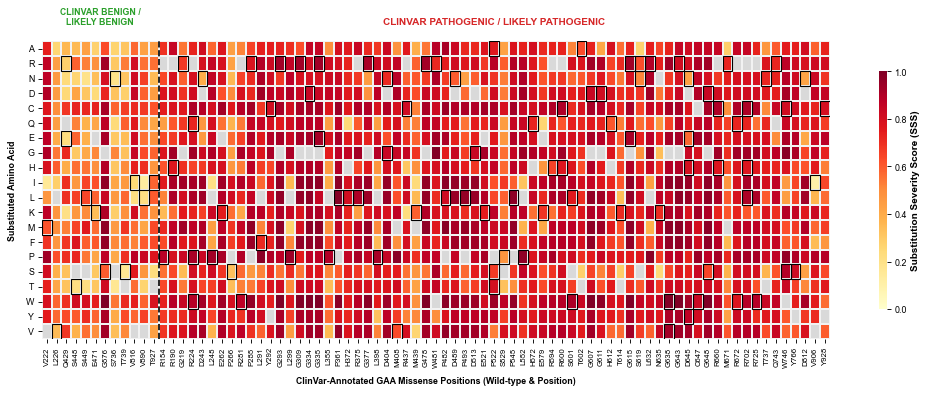

In [11]:
feat = read_processed("residue_features.csv").set_index("residue")
sss_long = read_processed("sss_all_substitutions.csv")
F.fig5c_clinvar_heatmap(sss_long, bench, feat)
plt.show()

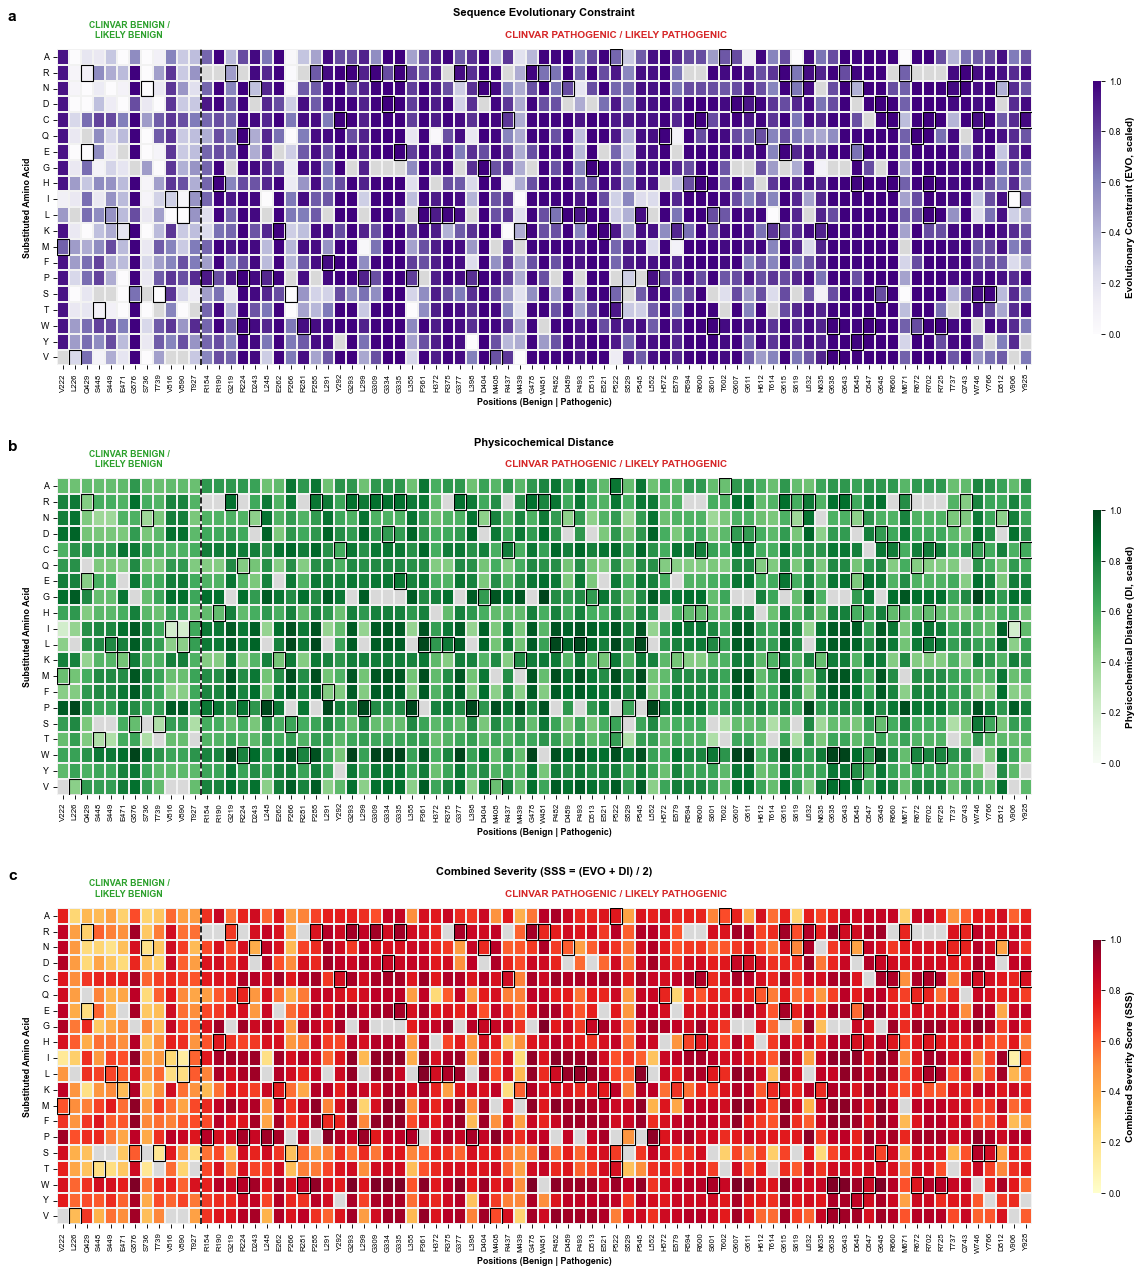

In [12]:
F.figS_clinvar_components(sss_long, bench, feat)
plt.show()

## 5. Variants of uncertain significance

In [13]:
vus = v[(v["class"] == "VUS") & v.SSS.notna()].copy()
vus["SSS class"] = np.select([vus.SSS < 0.5, vus.SSS <= 0.6], ["Benign (< 0.5)", "Unknown (0.5-0.6)"], "Severe (> 0.6)")
print(len(vus), "VUS inside the structure"); print(vus["SSS class"].value_counts().to_string())
print("\nSpearman r between SSS and AlphaMissense on the VUS:", round(ss.spearmanr(vus.SSS, vus.AlphaMissense, nan_policy="omit")[0], 3))
vus.sort_values("SSS", ascending=False).head(20)[["wt", "residue", "mt", "SSS", "AlphaMissense", "ESM-1v", "EVE"]].round(3)

358 VUS inside the structure
SSS class
Benign (< 0.5)       153
Severe (> 0.6)       142
Unknown (0.5-0.6)     63

Spearman r between SSS and AlphaMissense on the VUS: 0.681


,wt,residue,mt,SSS,AlphaMissense,ESM-1v,EVE
408,G,643,W,0.999,0.987,13.693,0.905
235,P,397,L,0.991,0.384,9.144,0.732
536,L,843,P,0.985,0.920,12.591,0.869
217,L,369,P,0.979,0.898,13.006,0.869
275,P,457,L,0.945,0.475,12.711,0.693
400,P,629,L,0.941,0.203,7.856,0.666
419,G,648,V,0.930,0.971,15.474,0.893
542,G,862,R,0.929,0.724,10.410,0.774
389,G,615,V,0.929,0.981,14.338,0.853
241,D,404,V,0.928,0.979,13.513,0.731
